# Solving a Commitment Cournot Game.

I am solving a simple Cournot game, where the demand function $P(Q)=a-bQ$ is simplified to $P(Q)=1-Q$. The optimal quantity and resulting profit are

| Game/Player            | Quantity                     | Profit                     |
|------------------------|------------------------------|----------------------------|
| **Cournot**            | $q^C = \frac{1}{3}$          | $\pi^C = \frac{1}{9}$      |
| **Stackelberg Leader** | $q^S_L = \frac{1}{2}$        | $\pi^S_L = \frac{1}{8}$    |
| **Stackelberg Follower** | $q^S_t = \frac{1}{4}$      | $\pi^S_t = \frac{1}{16}$   |

### Mixed Strategies
A mixed strategy Nash equilibrium mixing over Commit and Wait must satisfy the following:
$$
E\bigl[U_i(\text{commit to $q_i$})\bigr] = E\bigl[U_i(\text{Wait})\bigr]
$$ 

Furthermore, given that $-i$ commits to $q_{-i}$, the optimal quantity $q^*$ that $i$ should commit to must satisfy 

$$
q^*=arg \max_{q_i} \left\{p q_i (1 - q_i - {q_{-i}}) \;+\; (1 - p) q_i \frac{1 - q_i}{2}\right\}
$$

$$
s.t. \quad q_{-i} = q^*
$$

$p(q_i)$ is the probability of commiting, which is such that $E\bigl[U_i(\text{commit to }q_i\bigr)] = E\bigl[U_i(\text{Wait})\bigr]$, which equals 
$$
p(q_i) =
\begin{cases}
0, & \text{if } \displaystyle \frac{\tfrac12\,(q_i^2 - q_i) + \tfrac19}{-\tfrac74\,q_i^2 + q_i - \tfrac5{36}} < 0,\\[6pt]
\displaystyle \frac{\tfrac12\,(q_i^2 - q_i) + \tfrac19}{-\tfrac74\,q_i^2 + q_i - \tfrac5{36}}, 
& \text{if } 0 \le \frac{\tfrac12\,(q_i^2 - q_i) + \tfrac19}{-\tfrac74\,q_i^2 + q_i - \tfrac5{36}} \le 1,\\[6pt]
1, & \text{if } \displaystyle \frac{\tfrac12\,(q_i^2 - q_i) + \tfrac19}{-\tfrac74\,q_i^2 + q_i - \tfrac5{36}} > 1.
\end{cases}
$$

To find $q^*$, I must find the FOC.



# Solution

In [1]:
def prob(q):
    numerator = 0.5 * (q**2 - q) + 1/9
    denominator = -7/4 * q**2 + q - 5/36
    value = numerator / denominator
    if value < 0:
        return 0
    elif value > 1:
        return 1
    else:
        return value

def neg_payoff(q):
    p = prob(q)
    return - ( p * q * (1 - 2 * q) + (1 - p) * q * (1 - q) / 2 )

def foc(q):
    p = prob(q)
    return p * (1 - 3 * q) + (1 - p) * (1 - 2 * q) / 2

### Plot
Plotting the payoff function for different values of $q_i$.

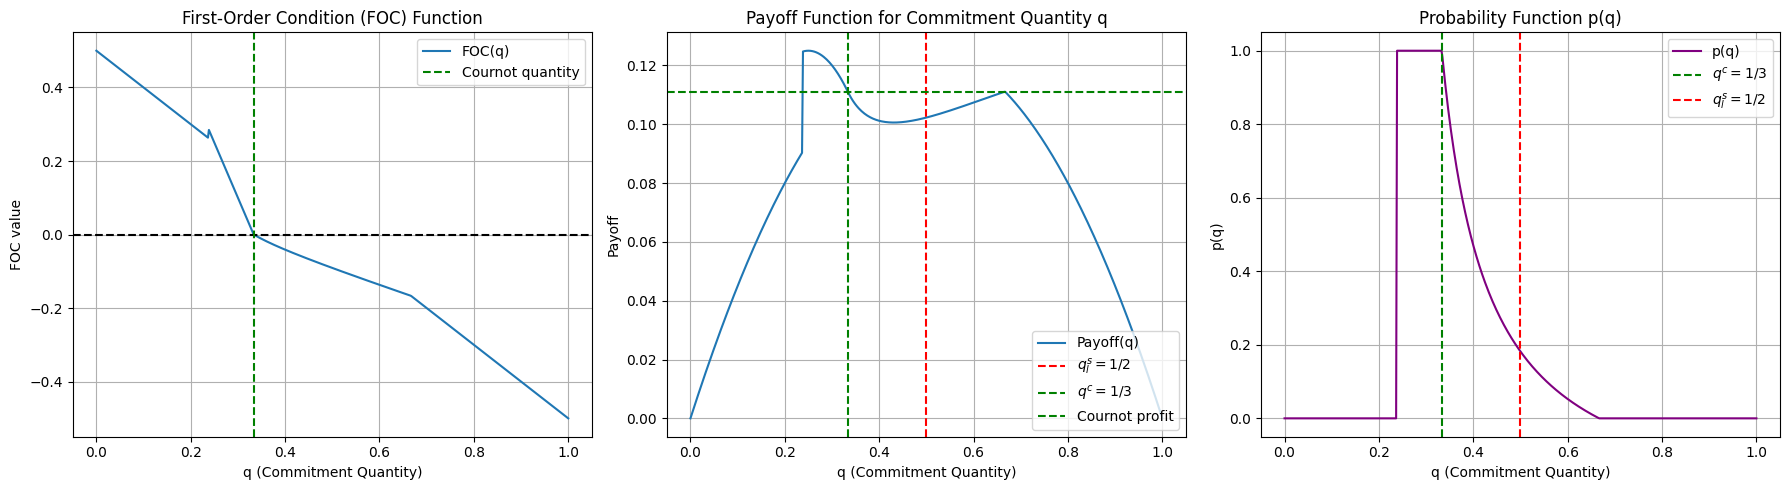

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Top subplot: FOC Function
axs[0].plot(q_values, foc_values, label="FOC(q)")
axs[0].axhline(0, color='black', linestyle='--')
axs[0].axvline(1/3, color='green', linestyle='--', label=r"Cournot quantity")
axs[0].set_xlabel("q (Commitment Quantity)")
axs[0].set_ylabel("FOC value")
axs[0].set_title("First-Order Condition (FOC) Function")
axs[0].legend()
axs[0].grid(True)

# Middle subplot: Payoff Function
axs[1].plot(q_values, actual_payoff, label="Payoff(q)")
axs[1].axvline(0.5, color='red', linestyle='--', label=r"$q^s_l=1/2$")
axs[1].axvline(1/3, color='green', linestyle='--', label=r"$q^c=1/3$")
axs[1].axhline(1/9, color='green', linestyle='--', label="Cournot profit")
axs[1].set_xlabel("q (Commitment Quantity)")
axs[1].set_ylabel("Payoff")
axs[1].set_title("Payoff Function for Commitment Quantity q")
axs[1].legend(loc='lower right')
axs[1].grid(True)

# Bottom subplot: Probability Function p(q)
axs[2].plot(q_values, p_values, label="p(q)", color='purple')
axs[2].axvline(1/3, color='green', linestyle='--', label=r"$q^c=1/3$")
axs[2].axvline(0.5, color='red', linestyle='--', label=r"$q^s_l=1/2$")
axs[2].set_xlabel("q (Commitment Quantity)")
axs[2].set_ylabel("p(q)")
axs[2].set_title("Probability Function p(q)")
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()


There is no true mixed strategy Nash equilibrium. Both players commit to $q^C$ in the first period.